# Solutions to notebook 7: Chebyshev series and the FFT

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/07_chebyshev_series_and_fft.ipynb)

Worked solutions to the exercises at the end of [notebook 7](../notebooks/07_chebyshev_series_and_fft.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct
from scipy.optimize import brentq
from scipy.special import ive

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 7
def cheb_coeffs(values):
    """Chebyshev coefficients a_k of the degree-N interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    if N == 0:
        return values.copy()
    a = dct(values, type=1) / N
    a[0] /= 2
    a[N] /= 2
    return a

def chop(coeffs, tol=1e-13):
    """Number of leading terms to keep so that every dropped coefficient is below tol times the largest."""
    size = np.abs(np.asarray(coeffs, dtype=float))
    significant = np.nonzero(size > tol * size.max())[0]
    return int(significant[-1]) + 1 if len(significant) else 1

def clenshaw(coeffs, x):
    """Evaluate the Chebyshev series with the given coefficients at the points x (scalar or array)."""
    x = np.asarray(x, dtype=float)
    b1, b2 = np.zeros_like(x), np.zeros_like(x)
    for a_k in coeffs[:0:-1]:                                        # a_N, a_{N-1}, ..., a_1
        b1, b2 = a_k + 2 * x * b1 - b2, b1
    return coeffs[0] + x * b1 - b2

def cheb_coeff_derivative(a):
    """Coefficients of p'(x) from the coefficients of p(x), by the backward recurrence."""
    a = np.asarray(a, dtype=float)
    N = len(a) - 1
    b = np.zeros(N + 1)
    if N == 0:
        return b
    b[N - 1] = 2 * N * a[N]
    for k in range(N - 2, -1, -1):
        b[k] = b[k + 2] + 2 * (k + 1) * a[k + 1]
    b[0] /= 2
    return b

def cheb_points(N):
    """The Chebyshev points x_j = cos(jπ/N); index 0 is x = +1 and index N is x = -1."""
    return np.cos(np.pi * np.arange(N + 1) / N)

## Exercise 1

Use $x = \tfrac12(z + z^{-1})$ to expand $x^4$ in Chebyshev polynomials by hand, and check
your answer with `cheb_coeffs` on a grid with $N = 6$.

Raise $x = \tfrac12(z + z^{-1})$ to the fourth power with the binomial theorem and collect the
terms in pairs $z^k + z^{-k} = 2T_k$:

$$x^4 = \frac{1}{16}\big(z^4 + 4z^2 + 6 + 4z^{-2} + z^{-4}\big)
= \frac{1}{16}\big(2T_4 + 8T_2 + 6T_0\big) = \tfrac38\,T_0 + \tfrac12\,T_2 + \tfrac18\,T_4 .$$

A grid with $N = 6$ represents every polynomial of degree up to 6 exactly, so `cheb_coeffs` must
return these three numbers and zeros elsewhere.

In [3]:
x = cheb_points(6)
a = cheb_coeffs(x**4)
print("coefficients of x⁴:", np.round(a, 12) + 0.0)

coefficients of x⁴: [0.375 0.    0.5   0.    0.125 0.    0.   ]


In [4]:
# verify: against the hand expansion, and against the power form of T_2 and T_4 at points off the grid
assert np.allclose(a, [3 / 8, 0, 1 / 2, 0, 1 / 8, 0, 0], atol=1e-14)
t = np.linspace(-1, 1, 11)
assert np.allclose(3 / 8 + (2 * t**2 - 1) / 2 + (8 * t**4 - 8 * t**2 + 1) / 8, t**4, atol=1e-14)

**Answer.** $x^4 = \tfrac38 T_0 + \tfrac12 T_2 + \tfrac18 T_4$, and `cheb_coeffs` returns
$(0.375, 0, 0.5, 0, 0.125, 0, 0)$. The binomial coefficients of $(z + z^{-1})^n$, divided by
$2^{n-1}$ (and by $2^n$ for the middle one), are the Chebyshev coefficients of $x^n$.

## Exercise 2

For $f(x) = 1/(1 + 25x^2)$ predict the decay rate $\rho$ of the Chebyshev coefficients from
the position of the poles. Measure it from the coefficients on a grid with $N = 300$, and
use `chop` to find the number of terms needed for a tolerance of $10^{-10}$.

The poles are at $x = \pm i/5$. The Bernstein ellipse through a point $ib$ on the imaginary
axis has $\rho = b + \sqrt{1 + b^2}$, so here $\rho = \tfrac15 + \sqrt{1 + \tfrac1{25}} = 1.2198$.
The function is even, so only the even coefficients are non-zero, and the rate is measured by a
straight-line fit to $\ln|a_k|$ over even $k$. If $|a_k| \approx C\rho^{-k}$, a relative
tolerance of $10^{-10}$ is reached after about $\ln 10^{10}/\ln\rho$ terms.

ρ predicted from the poles: 1.219804   measured: 1.219804
terms for a tolerance of 1e-10: chop gives 117, the estimate ln(1e10)/ln(ρ) gives 115.9


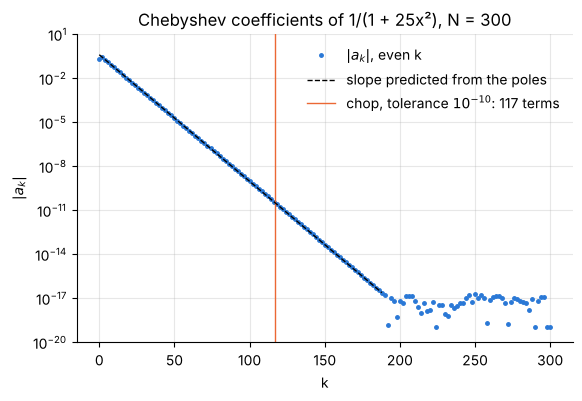

In [5]:
N = 300
a = np.abs(cheb_coeffs(1 / (1 + 25 * cheb_points(N) ** 2)))
even = np.arange(0, N + 1, 2)
window = even[(even >= 10) & (even <= 100)]
slope, intercept = np.polyfit(window, np.log(a[window]), 1)
rho_measured, rho_theory = np.exp(-slope), 1 / 5 + np.sqrt(1 + 1 / 25)
n_terms, n_predicted = chop(a, tol=1e-10), np.log(1e10) / np.log(rho_theory)
print(f"ρ predicted from the poles: {rho_theory:.6f}   measured: {rho_measured:.6f}")
print(f"terms for a tolerance of 1e-10: chop gives {n_terms}, the estimate ln(1e10)/ln(ρ) gives {n_predicted:.1f}")

fig, ax = plt.subplots()
ax.semilogy(even, np.maximum(a[even], 1e-19), ".", ms=5, label="$|a_k|$, even k")
ax.semilogy(even[:95], np.exp(intercept) * rho_theory ** (-even[:95].astype(float)), "--", color="k", lw=1, zorder=3, label="slope predicted from the poles")
ax.axvline(n_terms, color="#eb6834", lw=1, label=f"chop, tolerance $10^{{-10}}$: {n_terms} terms")
ax.set(xlabel="k", ylabel="$|a_k|$", ylim=(1e-20, 10), title="Chebyshev coefficients of 1/(1 + 25x²), N = 300")
ax.legend(frameon=False, loc="upper right");

In [6]:
# verify: the measured rate against the rate predicted from the poles, and the count against the estimate
assert abs(rho_measured / rho_theory - 1) < 1e-4
assert abs(n_terms - n_predicted) < 3
x_test = np.linspace(-1, 1, 1001)
truncation_error = np.abs(clenshaw(cheb_coeffs(1 / (1 + 25 * cheb_points(N) ** 2))[:n_terms], x_test) - 1 / (1 + 25 * x_test**2)).max()
print(f"largest error of the {n_terms}-term series on 1001 test points: {truncation_error:.1e}")
assert truncation_error < 1e-9

largest error of the 117-term series on 1001 test points: 7.9e-11


**Answer.** $\rho = (1 + \sqrt{26})/5 = 1.2198$, and the fit to the computed coefficients gives
the same number to six digits. `chop` asks for 117 terms (a polynomial of degree 116), against
the estimate of 116. The function of 7.3 with poles at $\pm i/2$ had $\rho = 1.618$ and
would need about 48: moving the poles 2.5 times closer to the interval costs 2.4 times as many terms.

## Exercise 3

A boundary layer of thickness $\varepsilon$ at $x = -1$ is modelled by
$u(x) = \exp\!\big(-(1+x)/\varepsilon\big)$. Using a grid with $N = 2048$ and `chop` with
tolerance $10^{-10}$, find the number of terms needed for $\varepsilon = 10^{-1}, 10^{-2},
10^{-3}$ and $10^{-4}$. How does the number scale with $\varepsilon$? Compare with the number
of equally spaced points needed to put ten points inside the layer.

Count the terms for each $\varepsilon$ and fit a power law. An equally spaced grid with ten
points inside the layer has spacing $\varepsilon/10$ over an interval of length 2, which is
$20/\varepsilon$ points. For the Chebyshev series, expect the count to follow the grid spacing
at the wall, which is $O(N^{-2})$: a layer of thickness $\varepsilon$ should need
$N = O(\varepsilon^{-1/2})$.

     ε     Chebyshev terms    terms × √ε    equally spaced points
  1e-01           24            7.59                200
  1e-02           69            6.90               2000
  1e-03          215            6.80              20000
  1e-04          679            6.79             200000
fitted scaling: terms ∝ ε^(-0.485)


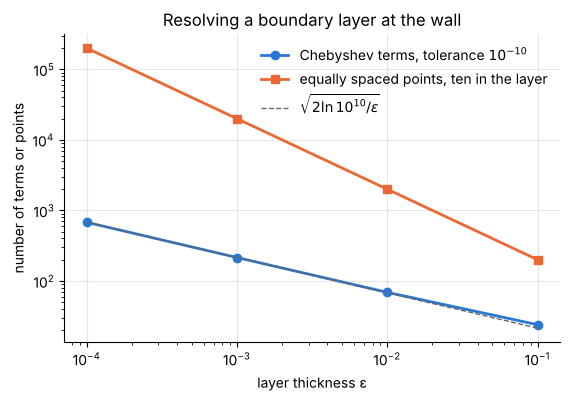

In [7]:
N = 2048
x = cheb_points(N)
epsilons = np.array([1e-1, 1e-2, 1e-3, 1e-4])
layer_coeffs = [cheb_coeffs(np.exp(-(1 + x) / eps)) for eps in epsilons]
terms = np.array([chop(a, tol=1e-10) for a in layer_coeffs])
equispaced = 20 / epsilons
exponent = np.polyfit(np.log(epsilons), np.log(terms), 1)[0]

print("     ε     Chebyshev terms    terms × √ε    equally spaced points")
for eps, n, m in zip(epsilons, terms, equispaced):
    print(f"{eps:7.0e} {n:12d} {n * np.sqrt(eps):15.2f} {m:18.0f}")
print(f"fitted scaling: terms ∝ ε^({exponent:.3f})")

fig, ax = plt.subplots()
ax.loglog(epsilons, terms, "o-", label="Chebyshev terms, tolerance $10^{-10}$")
ax.loglog(epsilons, equispaced, "s-", label="equally spaced points, ten in the layer")
ax.loglog(epsilons, np.sqrt(2 * np.log(1e10) / epsilons), "--", color="0.4", lw=1, label=r"$\sqrt{2\ln 10^{10}/\varepsilon}$")
ax.set(xlabel="layer thickness ε", ylabel="number of terms or points", title="Resolving a boundary layer at the wall")
ax.legend(frameon=False, loc="upper right");

The coefficients of this function are known in closed form, which gives an independent check
and explains the scaling. With $x = \cos\theta$ the function is
$e^{-1/\varepsilon}e^{-\cos\theta/\varepsilon}$, and the Fourier cosine coefficients of
$e^{-s\cos\theta}$ are modified Bessel functions:
$a_k = 2(-1)^k e^{-s}I_k(s)$ for $k \ge 1$ and $a_0 = e^{-s}I_0(s)$, with $s = 1/\varepsilon$.
For large $s$, $e^{-s}I_k(s) \approx e^{-k^2/(2s)}/\sqrt{2\pi s}$: the coefficients fall off as a
Gaussian in $k$ of width $\varepsilon^{-1/2}$, and they reach $10^{-10}$ of the largest at
$k = \sqrt{2\ln 10^{10}/\varepsilon} = 6.79\,\varepsilon^{-1/2}$.

In [8]:
# verify: the computed coefficients against the Bessel-function formula, and the count against the Gaussian estimate
for eps, a in zip(epsilons, layer_coeffs):
    k = np.arange(400)
    exact = 2 * (-1.0) ** k * ive(k, 1 / eps)                      # ive(k, s) = exp(-s) I_k(s)
    exact[0] /= 2
    assert np.abs(a[:400] - exact).max() < 1e-13
assert abs(exponent + 0.5) < 0.02
assert np.abs(terms[1:] / np.sqrt(2 * np.log(1e10) / epsilons[1:]) - 1).max() < 0.02

**Answer.** The series needs 24, 69, 215 and 679 terms for $\varepsilon = 10^{-1}, 10^{-2},
10^{-3}, 10^{-4}$: the count grows as $\varepsilon^{-1/2}$ (fitted exponent $-0.485$), close to $6.8/\sqrt\varepsilon$. An
equally spaced grid needs $20/\varepsilon$ points: 200, 2000, 20 000 and 200 000. For the
thinnest layer the Chebyshev grid is ahead by a factor of 300, because its points crowd
towards the wall with spacing $O(N^{-2})$, and it delivers ten digits where ten points per layer
with a low-order method would give two or three.

## Exercise 4

Running the identity of 7.7 the other way gives the coefficients of an antiderivative
$P(x) = \int p\,dx$: $A_k = (\gamma_{k-1}a_{k-1} - a_{k+1})/(2k)$ for $k \ge 1$, with
$\gamma_0 = 2$, $\gamma_k = 1$ otherwise and $a_{N+1} = a_{N+2} = 0$. Write
`cheb_coeff_integral(a)`, choosing $A_0$ so that $P(-1) = 0$, and check that
`cheb_coeff_derivative` undoes it. Use it with `clenshaw` to compute
$\int_{-1}^{1} e^{x}\sin 3x\,dx$ with $N = 24$ and compare with the exact value.

The antiderivative of a polynomial of degree $N$ has degree $N + 1$, so the function returns
$N + 2$ coefficients $A_0, \dots, A_{N+1}$. The formula fixes $A_1, \dots, A_{N+1}$. The constant
follows from $T_k(-1) = (-1)^k$: $P(-1) = \sum_k (-1)^kA_k = 0$ gives
$A_0 = -\sum_{k\ge1}(-1)^kA_k$. With that choice $P(x) = \int_{-1}^{x}p$, and the integral over
the whole interval is $P(1)$.

In [9]:
def cheb_coeff_integral(a):
    """Coefficients A_0..A_{N+1} of the antiderivative P of the series with coefficients a, with P(-1) = 0."""
    a = np.asarray(a, dtype=float)
    N = len(a) - 1
    k = np.arange(1, N + 2)
    gamma = np.where(k == 1, 2.0, 1.0)                              # γ_{k-1} for k = 1, ..., N+1
    a_next = np.concatenate([a[2:], [0.0, 0.0]])                    # a_{k+1}, with a_{N+1} = a_{N+2} = 0
    A = np.zeros(N + 2)
    A[1:] = (gamma * a - a_next) / (2 * k)
    A[0] = -np.sum((-1.0) ** k * A[1:])                             # P(-1) = Σ (-1)^k A_k = 0
    return A

N = 24
x = cheb_points(N)
a = cheb_coeffs(np.exp(x) * np.sin(3 * x))
A = cheb_coeff_integral(a)
antiderivative = lambda x: np.exp(x) * (np.sin(3 * x) - 3 * np.cos(3 * x)) / 10       # d/dx of this is exp(x) sin 3x
integral, integral_exact = clenshaw(A, 1.0), antiderivative(1.0) - antiderivative(-1.0)
print(f"∫ exp(x) sin 3x dx over [-1, 1]:  series {integral:.15f}   exact {integral_exact:.15f}   difference {abs(integral - integral_exact):.1e}")

∫ exp(x) sin 3x dx over [-1, 1]:  series 0.741616128546381   exact 0.741616128546381   difference 1.1e-16


In [10]:
# verify: a known case, the round trip through cheb_coeff_derivative, the exact integral, and P(x) for all x
assert np.allclose(cheb_coeff_integral([0, 1.0]), [-1 / 4, 0, 1 / 4])       # ∫ x dx from -1 is (x² - 1)/2 = (T_2 - T_0)/4
assert np.allclose(cheb_coeff_derivative(A), np.append(a, 0), atol=1e-14)   # differentiation undoes integration
assert abs(clenshaw(A, -1.0)) < 1e-13
assert abs(integral - integral_exact) < 1e-14
x_test = np.linspace(-1, 1, 201)
assert np.abs(clenshaw(A, x_test) - (antiderivative(x_test) - antiderivative(-1.0))).max() < 1e-14

**Answer.** $\int_{-1}^{1}e^x\sin 3x\,dx = 0.7416161285$, and the series with $N = 24$ agrees
with the exact value $\big[e^x(\sin 3x - 3\cos 3x)/10\big]_{-1}^{1}$ to rounding error. The same
two lines give the running integral $\int_{-1}^{x}$ at any $x$, which a quadrature rule does
not. Notebook 10 turns the special case $P(1)$ into the Clenshaw-Curtis weights.

## Exercise 5

The Colebrook equation for the Darcy friction factor of turbulent pipe flow,
$1/\sqrt f = -2\log_{10}\!\big(\tfrac{\epsilon/D}{3.7} + \tfrac{2.51}{Re\sqrt f}\big)$, has to
be solved iteratively. For relative roughness $\epsilon/D = 10^{-4}$, sample $f$ at
Chebyshev points in the variable $\log_{10}Re$ over $4\times10^3 \le Re \le 10^8$ (solve
the equation at each point with `scipy.optimize.brentq`), using $N = 64$. How many terms
of the series give a relative error below $10^{-6}$ on a fine grid of 2000 Reynolds
numbers? Evaluate the series with `clenshaw`.

This is the worked example of 7.6 with a function that is expensive to evaluate. Map
$\log_{10}Re \in [\log_{10}4000, 8]$ to $x \in [-1, 1]$, solve the equation at the 65 Chebyshev
points, and transform to coefficients. Then truncate the series at increasing lengths and
measure the error against direct solutions on 2000 Reynolds numbers equally spaced in
$\log_{10}Re$. The friction factor varies only by a factor of about three over the range, so
there is no need to work with its logarithm.

friction factor: 0.04001 at Re = 4e3, 0.011999 at Re = 1e8
terms needed for a relative error below 1e-6: 17   (error 8.9e-07; with one term fewer 1.8e-06)
chop with tolerance 1e-6 suggests 16 terms;  error of the full 65-term series: 2.6e-14


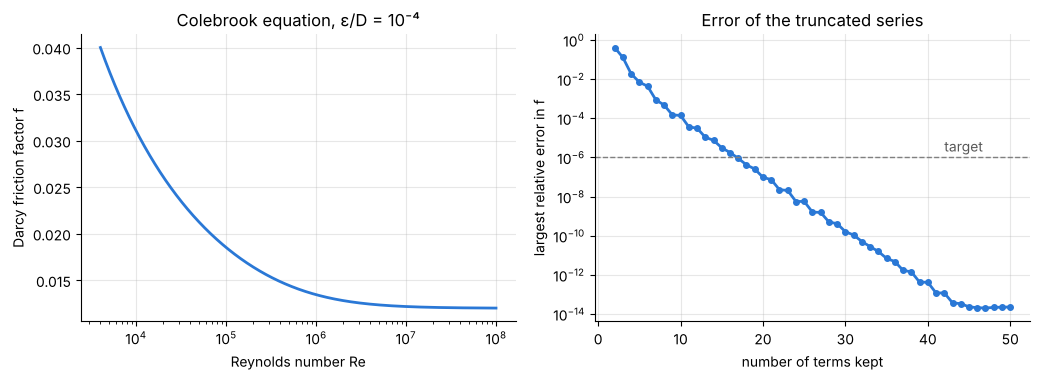

In [11]:
roughness = 1e-4
colebrook_residual = lambda f, Re: 1 / np.sqrt(f) + 2 * np.log10(roughness / 3.7 + 2.51 / (Re * np.sqrt(f)))

def friction_factor(Re):
    """Darcy friction factor from the Colebrook equation, solved by bracketing."""
    return brentq(colebrook_residual, 0.005, 0.1, args=(Re,), xtol=1e-15, rtol=1e-14)

log_low, log_high = np.log10(4e3), 8.0
to_Re = lambda x: 10 ** ((log_high + log_low) / 2 + (log_high - log_low) / 2 * x)

N = 64
coeffs = cheb_coeffs([friction_factor(Re) for Re in to_Re(cheb_points(N))])

x_test = np.linspace(-1, 1, 2000)
Re_test = to_Re(x_test)
f_test = np.array([friction_factor(Re) for Re in Re_test])
terms_tried = np.arange(2, 51)
errors = np.array([np.abs(clenshaw(coeffs[:n], x_test) / f_test - 1).max() for n in terms_tried])
n_needed = int(terms_tried[np.argmax(errors < 1e-6)])
full_error = np.abs(clenshaw(coeffs, x_test) / f_test - 1).max()               # all 65 terms
print(f"friction factor: {f_test[0]:.5f} at Re = 4e3, {f_test[-1]:.6f} at Re = 1e8")
print(f"terms needed for a relative error below 1e-6: {n_needed}   (error {errors[n_needed - 2]:.1e}; with one term fewer {errors[n_needed - 3]:.1e})")
print(f"chop with tolerance 1e-6 suggests {chop(coeffs, tol=1e-6)} terms;  error of the full 65-term series: {full_error:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
axes[0].semilogx(Re_test, f_test)
axes[0].set(xlabel="Reynolds number Re", ylabel="Darcy friction factor f", title="Colebrook equation, ε/D = 10⁻⁴")
axes[1].semilogy(terms_tried, errors, "o-", ms=4)
axes[1].axhline(1e-6, color="0.5", lw=1, ls="--")
axes[1].annotate("target", xy=(42, 2e-6), color="0.35")
axes[1].set(xlabel="number of terms kept", ylabel="largest relative error in f", title="Error of the truncated series")
fig.tight_layout()

In [12]:
# verify: the truncated series satisfies the Colebrook equation itself, the count is sharp, and two limiting values
f_series = clenshaw(coeffs[:n_needed], x_test)
assert np.abs(f_series / f_test - 1).max() < 1e-6 <= errors[n_needed - 3]
assert np.abs(colebrook_residual(f_series, Re_test)).max() < 1e-4            # residual in 1/√f, which is between 5 and 9.1
f_rough = (2 * np.log10(3.7 / roughness)) ** -2                              # fully rough limit, Re → ∞
print(f"fully rough limit: f = {f_rough:.6f};  series at Re = 1e8: {f_series[-1]:.6f}")
assert 0 < f_series[-1] / f_rough - 1 < 2e-3
assert abs(f_series[0] / 0.3164 * 4000**0.25 - 1) < 0.02                     # Blasius smooth-pipe correlation at Re = 4000
assert full_error < 1e-12                                                  # N = 64 resolves f to rounding error

fully rough limit: f = 0.011980;  series at Re = 1e8: 0.011999


**Answer.** Seventeen terms give a relative error of $9\times10^{-7}$ over the whole range
$4\times10^3 \le Re \le 10^8$, and sixteen do not ($1.8\times10^{-6}$); `chop` applied to the
coefficients alone suggests 16. The full 65-term series is accurate to $3\times10^{-14}$, so
$N = 64$ was more than enough to sample from. Evaluating 17 terms with `clenshaw` costs 17
multiplications and no iteration, and the result is a smooth function of $Re$ with a smooth
derivative, which a solver calling it inside a pipe-network calculation will appreciate. A
series like this is valid only for the roughness and the range it was built for.